In [1]:
from pathlib import Path
from torchvision.datasets import CIFAR10

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"

train_data = CIFAR10(root=str(data_dir), train=True, download=False)
test_data = CIFAR10(root=str(data_dir), train=False, download=False)

print("Số ảnh Train:", len(train_data))
print("Số ảnh Test:", len(test_data))
print("Các lớp:", train_data.classes)


Số ảnh Train: 50000
Số ảnh Test: 10000
Các lớp: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [2]:
from collections import Counter

train_counts = Counter(train_data.targets)
test_counts = Counter(test_data.targets)

print(f"{'Lớp':<12} {'Train':>8} {'Test':>8}")
for label_id, class_name in enumerate(train_data.classes):
    print(f"{class_name:<12} {train_counts[label_id]:>8,} {test_counts[label_id]:>8,}")

Lớp             Train     Test
airplane        5,000    1,000
automobile      5,000    1,000
bird            5,000    1,000
cat             5,000    1,000
deer            5,000    1,000
dog             5,000    1,000
frog            5,000    1,000
horse           5,000    1,000
ship            5,000    1,000
truck           5,000    1,000


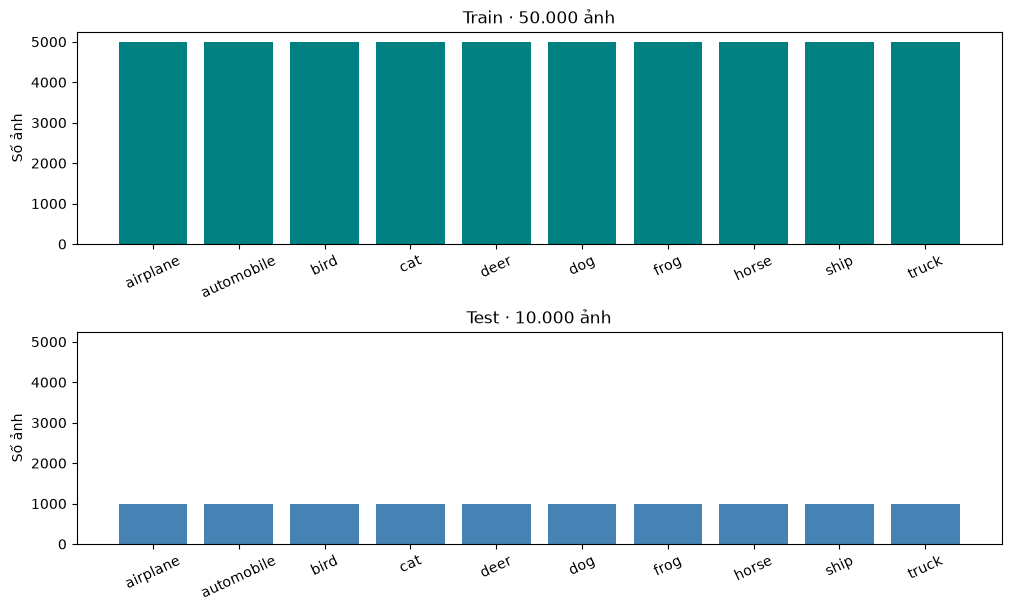

In [3]:
import matplotlib.pyplot as plt

class_names = train_data.classes
train_values = [train_counts[i] for i in range(len(class_names))]
test_values = [test_counts[i] for i in range(len(class_names))]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharey=True, layout="constrained")

axes[0].bar(class_names, train_values, color="teal")
axes[0].set_title("Train · 50.000 ảnh")

axes[1].bar(class_names, test_values, color="steelblue")
axes[1].set_title("Test · 10.000 ảnh")

for ax in axes:
    ax.set_ylabel("Số ảnh")
    ax.tick_params(axis="x", labelrotation=25)

plt.show()

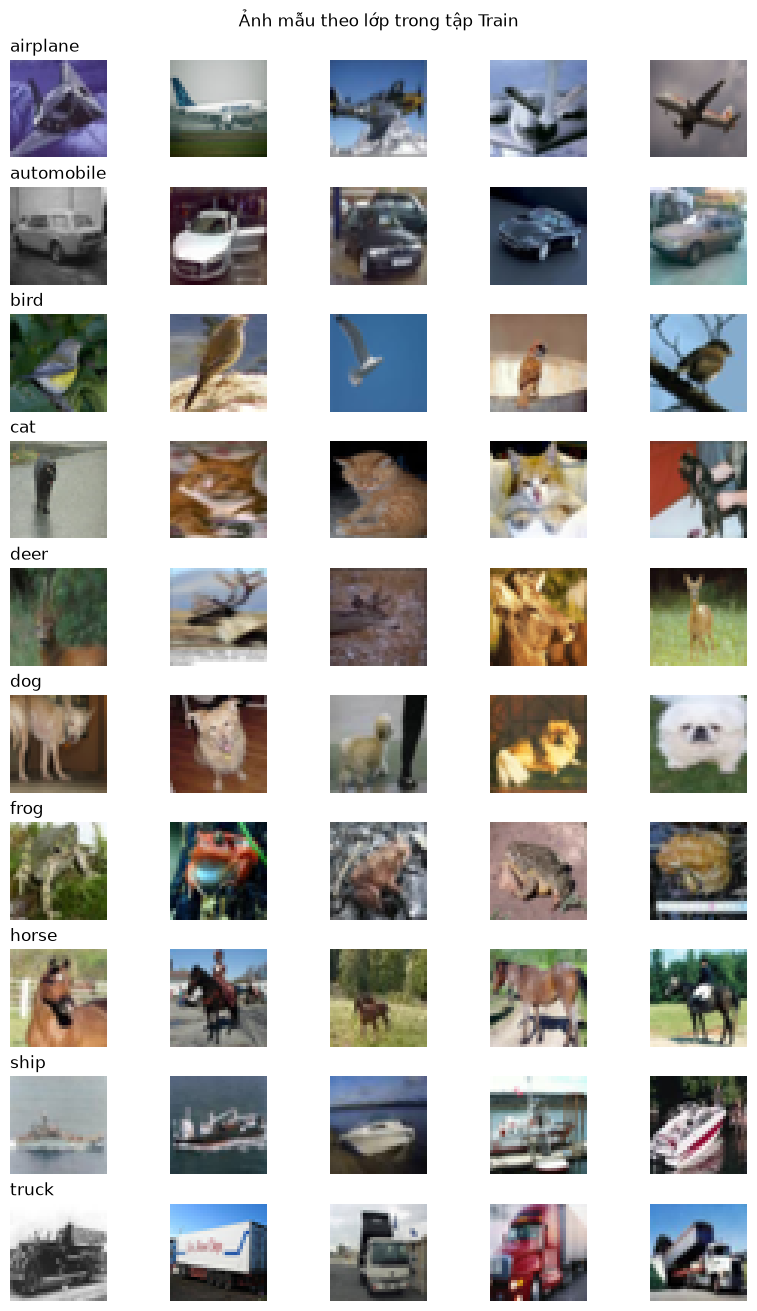

In [4]:
import numpy as np

rng = np.random.default_rng(42)
train_labels = np.asarray(train_data.targets)
samples_per_class = 5

sample_fig, sample_axes = plt.subplots(
    len(class_names), samples_per_class,
    figsize=(8, 13), layout="constrained"
)
sample_fig.suptitle("Ảnh mẫu theo lớp trong tập Train")

for class_id, class_name in enumerate(class_names):
    class_indices = np.flatnonzero(train_labels == class_id)
    chosen_indices = rng.choice(class_indices, size=samples_per_class, replace=False)

    for ax, image_index in zip(sample_axes[class_id], chosen_indices):
        ax.imshow(train_data.data[image_index])
        ax.axis("off")

    sample_axes[class_id, 0].set_title(class_name, loc="left")

plt.show()

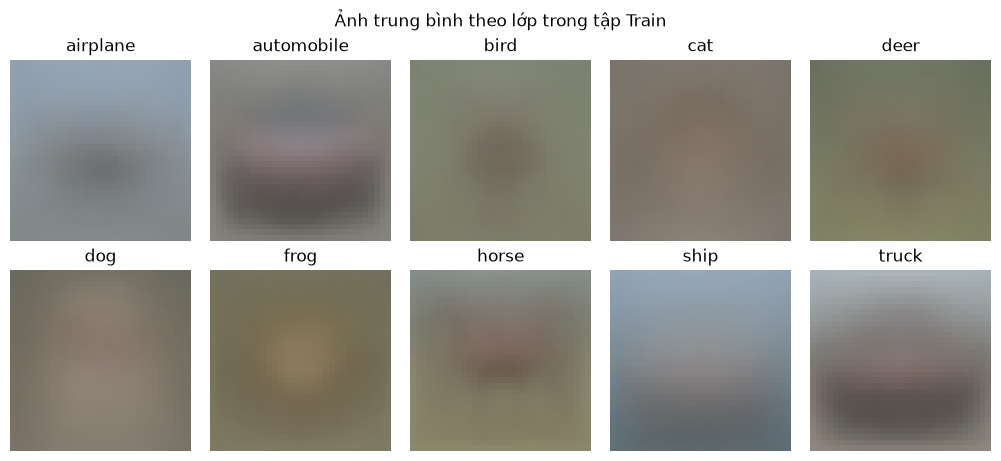

In [5]:
mean_fig, mean_axes = plt.subplots(
    2, 5, figsize=(10, 4.5), layout="constrained"
)
mean_fig.suptitle("Ảnh trung bình theo lớp trong tập Train")

for class_id, class_name in enumerate(class_names):
    class_images = train_data.data[train_labels == class_id]
    mean_image = class_images.mean(axis=0)

    ax = mean_axes.flat[class_id]
    ax.imshow(mean_image / 255)
    ax.set_title(class_name)
    ax.axis("off")

plt.show()

Train
  R: Mean = 125.31, Std = 62.99
  G: Mean = 122.95, Std = 62.09
  B: Mean = 113.87, Std = 66.70
Test
  R: Mean = 126.02, Std = 62.90
  G: Mean = 123.71, Std = 61.94
  B: Mean = 114.85, Std = 66.71


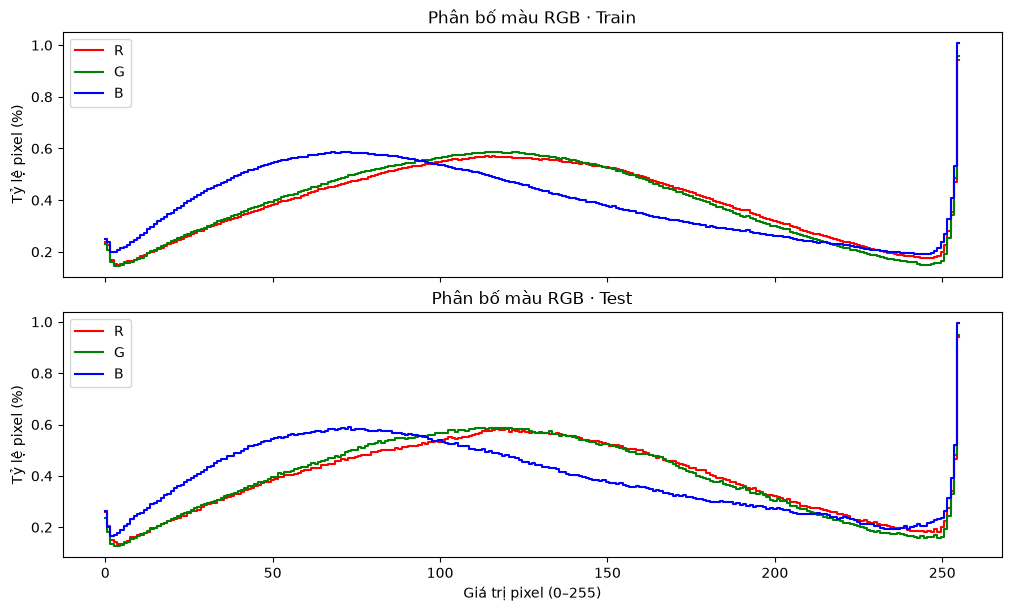

In [6]:
levels = np.arange(256)
channels = [("R", "red"), ("G", "green"), ("B", "blue")]

rgb_fig, rgb_axes = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, layout="constrained"
)

for ax, (split_name, dataset) in zip(
    rgb_axes, [("Train", train_data), ("Test", test_data)]
):
    print(split_name)

    for channel_id, (channel_name, color) in enumerate(channels):
        pixels = dataset.data[..., channel_id].ravel()
        counts = np.bincount(pixels, minlength=256)

        mean = np.average(levels, weights=counts)
        std = np.sqrt(np.average((levels - mean) ** 2, weights=counts))
        print(f"  {channel_name}: Mean = {mean:.2f}, Std = {std:.2f}")

        ax.step(levels, 100 * counts / counts.sum(),
                where="mid", color=color, label=channel_name)

    ax.set_title(f"Phân bố màu RGB · {split_name}")
    ax.set_ylabel("Tỷ lệ pixel (%)")
    ax.legend()

rgb_axes[-1].set_xlabel("Giá trị pixel (0–255)")
plt.show()

In [7]:
for split_name, dataset in [("Train", train_data), ("Test", test_data)]:
    images = dataset.data

    # Tìm giá trị nhỏ nhất và lớn nhất của từng kênh trong mỗi ảnh.
    channel_min = images.min(axis=(1, 2))
    channel_max = images.max(axis=(1, 2))
    solid_color = (channel_min == channel_max).all(axis=1)

    print(f"{split_name}")
    print(f"  Kích thước mảng: {images.shape}")
    print(f"  Kiểu dữ liệu: {images.dtype}")
    print(f"  Khoảng giá trị pixel: {images.min()}–{images.max()}")
    print(f"  Số ảnh một màu: {solid_color.sum():,}")

Train
  Kích thước mảng: (50000, 32, 32, 3)
  Kiểu dữ liệu: uint8
  Khoảng giá trị pixel: 0–255
  Số ảnh một màu: 0
Test
  Kích thước mảng: (10000, 32, 32, 3)
  Kiểu dữ liệu: uint8
  Khoảng giá trị pixel: 0–255
  Số ảnh một màu: 0


In [8]:
from hashlib import sha256

def hash_images(dataset):
    return [sha256(image.tobytes()).digest() for image in dataset.data]

train_hashes = hash_images(train_data)
test_hashes = hash_images(test_data)

unique_train = set(train_hashes)
unique_test = set(test_hashes)
shared_hashes = unique_train & unique_test

print(f"Số bản sao dư trong Train: {len(train_hashes) - len(unique_train):,}")
print(f"Số bản sao dư trong Test: {len(test_hashes) - len(unique_test):,}")
print(f"Số nội dung ảnh trùng giữa Train và Test: {len(shared_hashes):,}")

Số bản sao dư trong Train: 0
Số bản sao dư trong Test: 0
Số nội dung ảnh trùng giữa Train và Test: 0


In [9]:
output_dir = project_dir / "results" / "eda" / "notebook"
output_dir.mkdir(parents=True, exist_ok=True)

chart_path = output_dir / "class_distribution.png"
fig.savefig(chart_path, dpi=160, bbox_inches="tight")

print(f"Đã lưu biểu đồ: {chart_path}")

Đã lưu biểu đồ: c:\Users\homin\Downloads\Practice-2---Hands-on-practice-with-pre-trained-neural-network-architectures-main (1)\Practice-2---Hands-on-practice-with-pre-trained-neural-network-architectures-main\results\eda\notebook\class_distribution.png
